In [32]:
#Блок імпорту бібліотек
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

In [27]:
#Формування набір даних з випадковими значеннями
np.random.seed(42)

x = np.linspace(0, 100, 1000)
y = x*0.5 + np.random.normal(0, 10, 1000)

In [28]:
#Нормалізація
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x.reshape(-1, 1))

In [29]:
#Розділення на дослідну та тестову вибірки
x_train, x_test, y_train, y_test = train_test_split(
    x_scaled, y, test_size=0.2, random_state=42
)

In [39]:
#Тренування моделі з різними K
best_rmse = float('inf')
best_k = None
for k in [1, 3, 5, 9, 11, 15, 17, 21]:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(x_train, y_train)
    y_pred = knn.predict(x_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    if rmse < best_rmse:
        best_rmse = rmse
        best_k = k

In [40]:
#Найоптимальніше K
print(best_k, best_rmse)

15 9.746042616647436


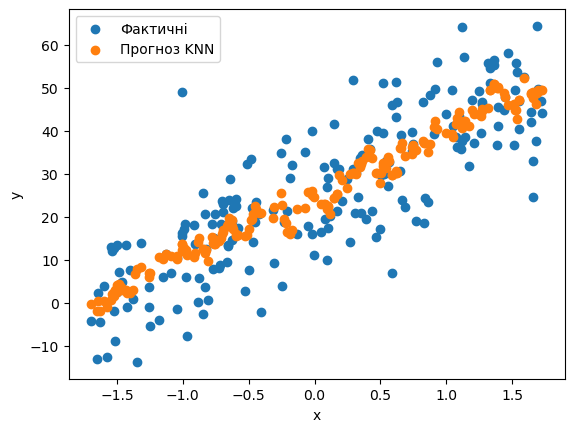

In [42]:
#Візулізація
knn = KNeighborsRegressor(n_neighbors=best_k)
knn.fit(x_train, y_train)

y_pred = knn.predict(x_test)

plt.scatter(x_test, y_test, label="Фактичні")
plt.scatter(x_test, y_pred, label="Прогноз KNN")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()